In [70]:
from config import *
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

## Load in Pair Data and Control Data

In [71]:
parent = Table.read('out/parent.fits', unit_parse_strict = 'silent')
pairs = Table.read('out/pairs.fits', unit_parse_strict = 'silent')

# Get the indices of the primary galaxies and their matched controls
ctrl_indices = np.asarray(pairs['control_index'])
matched = ctrl_indices[:, 0] != -1
p = np.asarray(pairs['primary_index'])[matched]
c = ctrl_indices[matched]

## Calculate SFRs

The sSFR enhancement is given by
$$ \Delta \log(\text{sSFR}) = \log(\text{sSFR}_\text{pair}) - \langle \log(\text{sSFR}_\text{ctrl}) \rangle _\text{med} $$
(Puskas et al. 2025)

In [72]:
log_SFR = np.asarray(parent['SFR_0_1Gyr_percentile50'], dtype = float)
logM = np.asarray(parent['logmstar'], dtype = float)
log_sSFR = log_SFR - logM

Delta_log_sSFR = log_sSFR[p] - np.median(log_sSFR[c], axis = 1)

## Calculate Uncertainties

The uncertainty in the SFR is given by
$$ \sigma_{\log\text{SFR}} = \frac{1}{2} (p_{84} - p_{16}) $$
The uncertainty in the sSFR is given by
$$ \sigma_{\log\text{sSFR}} = \sqrt{\sigma_{\log\text{SFR}}^2 + \sigma_{\log M_\star}^2} $$
The uncertainty in the sSFR enhancement is given by
$$ \sigma_{\Delta \log\text{sSFR}} = \sqrt{\sigma_\text{pair}^2 + \sigma_\text{med}^2} $$
$$ \sigma_\text{med} \approx 1.2 \frac{\sqrt{\langle \sigma_\text{ctrl}^2 \rangle}}{\sqrt{5}} $$

In [73]:
p16 = np.asarray(parent['SFR_0_1Gyr_percentile16'], dtype = float)
p84 = np.asarray(parent['SFR_0_1Gyr_percentile84'], dtype = float)

# Calculate the uncertainty in the sSFR for the primary galaxies and their controls
sigma_log_SFR = 0.5 * (p84 - p16)
sigma_logM = np.asarray(parent['dellogmstar'], dtype = float)
sigma_log_sSFR = np.sqrt(sigma_log_SFR ** 2 + sigma_logM ** 2)

# Calculate the uncertainty in the sSFR enhancement
sigma_pair = sigma_log_sSFR[p]
sigma_med = 1.2 * np.sqrt(np.mean(sigma_log_sSFR[c] ** 2, axis = 1)) / np.sqrt(N_CTRL)
sigma_Delta_log_sSFR = np.sqrt(sigma_pair ** 2 + sigma_med ** 2)

## Save Data to File

In [74]:
sfr_magphys = Table({'primary_index': p, 'control_index': c, 'rp': np.asarray(pairs['rp'])[matched], 
                     'Delta_log_sSFR': Delta_log_sSFR, 'sigma_Delta_log_sSFR': sigma_Delta_log_sSFR,
                     'log_sSFR_primary': log_sSFR[p], 'log_sSFR_controls': log_sSFR[c],
                     'sigma_log_sSFR_primary': sigma_log_sSFR[p], 'sigma_log_sSFR_controls': sigma_log_sSFR[c]})
sfr_magphys.write('out/sfr_magphys.fits', overwrite = True)

## Diagnostic Plots

In [75]:
# Global plot style
plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

# Method to bold the tick labels
def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

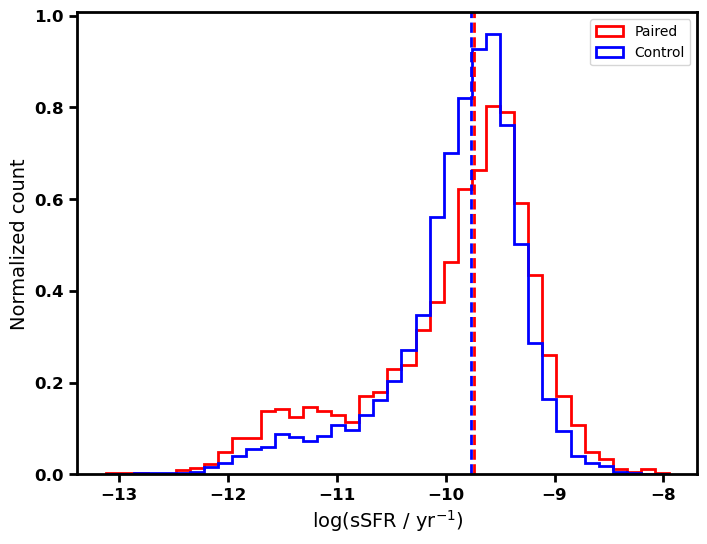

In [76]:
# Plot the log sSFR distributions of the paired and control galaxies
fig, ax = plt.subplots(figsize = (8, 6))

log_sSFR_pair = log_sSFR[p]
log_sSFR_ctrl = log_sSFR[c].ravel()

bins = np.histogram_bin_edges(np.concatenate([log_sSFR_pair, log_sSFR_ctrl]), bins = 40)
ax.hist(log_sSFR_pair, bins = bins, density = True, histtype = 'step', linewidth = 2, color = 'red', label = 'Paired')
ax.hist(log_sSFR_ctrl, bins = bins, density = True, histtype = 'step', linewidth = 2, color = 'blue', label = 'Control')

# Median of each distribution
ax.axvline(np.median(log_sSFR_pair), color = 'red', linestyle = '--', linewidth = 2)
ax.axvline(np.median(log_sSFR_ctrl), color = 'blue', linestyle = '--', linewidth = 2)

ax.set_xlabel(r'log(sSFR / yr$^{-1}$)')
ax.set_ylabel('Normalized count')
ax.legend()

bold_ticks(ax)

plt.savefig("figs/magphys_sfr_distribution.pdf", format = "pdf", bbox_inches = "tight")
plt.savefig("figs/magphys_sfr_distribution.png", format = "png", bbox_inches = "tight")

plt.show()